# Лабораторная работа 7. Рекомендательная система для медиакаталога

**Задача (практика 7).** Разработать рекомендательную систему для медиакаталога.
На реальных данных сравнить три подхода — контентный TF-IDF, коллаборативный SVD
и item-based ALS — с бейзлайном «популярное». Проверить качество топ-K на оценках,
отложенных по времени, и выяснить, как длина истории пользователя влияет на
результат, охват каталога и разнообразие выдачи.

**Результат.** На MovieLens обработано 100 836 оценок от 610 пользователей
по каталогу из 9 742 фильмов. В тесте оценены рекомендации для 116 пользователей.
По NDCG@10 лидирует бейзлайн «популярное» (0,3338), а ALS при близком значении
(0,3282) показала 207 разных фильмов против 71 у бейзлайна. У 88 пользователей
до даты отсечения нет истории, поэтому все модели дали им одинаковую выдачу.
В группе с 20 и более оценками у ALS NDCG@10 составила 0,0767 против 0,0722
у бейзлайна. Интервал разницы включает ноль.

| Требование задания | Что получилось и где смотреть |
|---|---|
| Выбор датасета и его обоснование | MovieLens с оценками, названиями, жанрами и временем взаимодействий. Раздел «Задача и данные» |
| Анализ данных | Распределение оценок, активность пользователей и разреженность матрицы 98,30%. Рис. 1 |
| Честное разбиение | 80 668 ранних оценок для обучения, 20 168 поздних для теста. Раздел «Протокол эксперимента» |
| Три модели и бейзлайн | TF-IDF, Surprise SVD, item-based ALS и популярное. Раздел «Протокол эксперимента» |
| Оценка ранжирования | Precision@K, Recall@K, MAP@K и NDCG@K при K = 5, 10 и 20. Разделы «Качество ранжирования» и «Качество по длине истории» |
| Покрытие и разнообразие | Доля показанных фильмов, доля выдачи за пределами популярных 10% и разнообразие жанров. Рис. 4 |
| Ручная проверка и пузырь фильтров | Две выдачи с отметками попаданий и пример, где TF-IDF поставил в начало списка фильмы одной серии. Разделы «Разбор двух выдач» и «Покрытие и разнообразие» |
| Материалы для сдачи | CLI `recsys.py`, таблица `results/metrics.csv`, выдачи `results/recs.json` и [отчёт на 7 страниц](report.pdf) |

Ниже приведены данные, методика, графики, два примера рекомендаций и заключение.
Для повторного расчёта надо установить зависимости из `requirements.txt` и задать
`RECALCULATE = True` в первой ячейке кода. Текстовые выводы относятся
к сохранённому эксперименту.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

LAB = Path.cwd()
if not (LAB / "recsys.py").exists():
    LAB = LAB / "lab7"

RECALCULATE = False
if RECALCULATE:
    subprocess.run([sys.executable, "recsys.py", "--model", "all",
                    "--k", "5", "10", "20", "--evaluate"], cwd=LAB, check=True)

OUT = LAB / "results"
metrics = pd.read_csv(OUT / "metrics.csv")
summary = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))
examples = json.loads((OUT / "recs.json").read_text(encoding="utf-8"))["examples"]
names = {"popular": "Популярное", "content": "TF-IDF",
         "svd": "SVD", "als": "ALS item-based"}

## Задача и данные

Сравниваем три способа персонализации с популярными фильмами. Основной вопрос — повышают ли модели качество топ-10 и сколько разных фильмов они показывают. Для релевантности используем оценку пользователя от четырёх звёзд.

In [2]:
display(pd.DataFrame([{
    "Оценки": summary["ratings"], "Пользователи": summary["users"],
    "Фильмы": summary["movies"], "Пустые ячейки, %": round(summary["sparsity"] * 100, 2),
}]))

,Оценки,Пользователи,Фильмы,"Пустые ячейки, %"
0,100836,610,9742,98.3


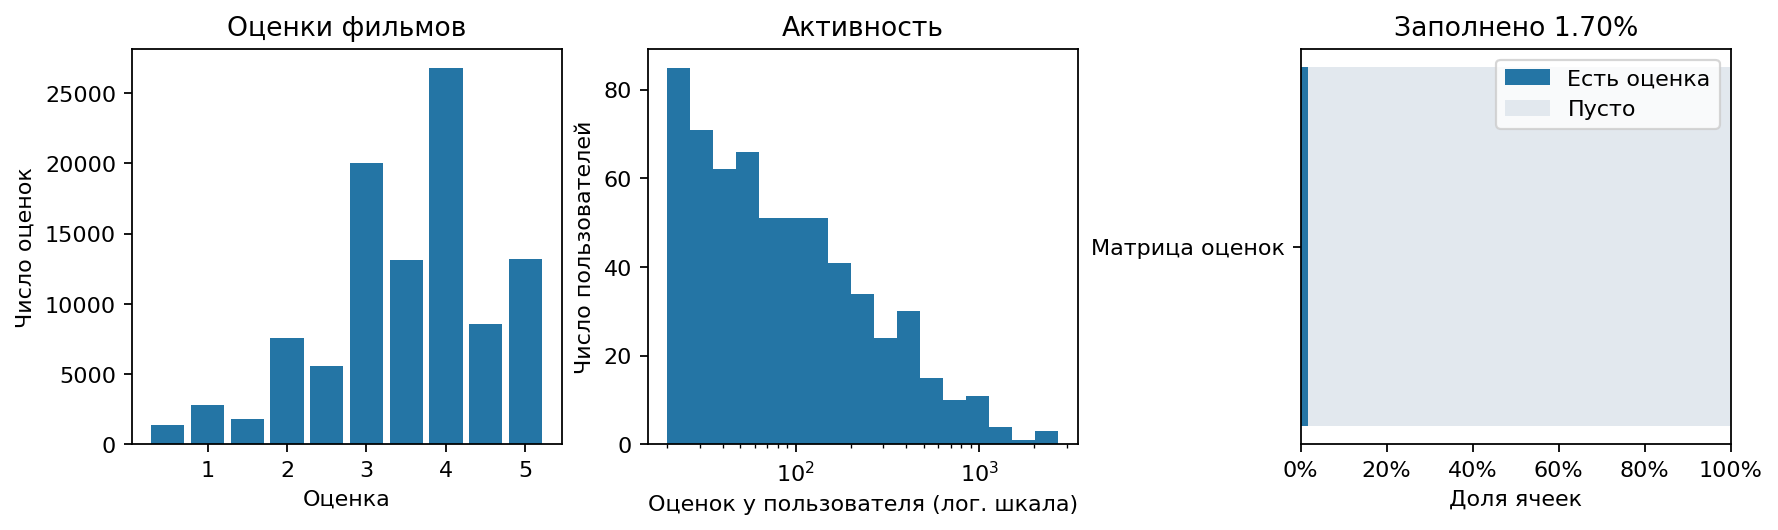

In [3]:
display(Image(filename=str(OUT / "data.png"), width=980))

*Рис. 1. Распределение оценок, активность пользователей и заполненность матрицы «пользователь × фильм».*

У половины пользователей не больше примерно 71 оценки, у четверти — не больше 35, а максимум достигает 2 698. Поэтому среднее число оценок даёт завышенное представление о длине типичной истории. При заполненности матрицы 1,70% большая часть пар «пользователь × фильм» остаётся ненаблюдаемой.

MovieLens выбран из-за сочетания явных оценок, времени их выставления и метаданных фильмов. Названия и жанры достаточны для простой контентной модели, но передают меньше информации о содержании фильма, чем описание или аннотация.

## Протокол эксперимента

Один временной порог для всех пользователей — 22.03.2016, 08:26:11 UTC. Обучение использует оценки строго до порога, тест — оценки начиная с порога. Таким образом, при прогнозе для пользователя модель не видит будущих взаимодействий других пользователей.

In [4]:
display(pd.DataFrame([{
    "Обучение": summary["train_ratings"], "Тест": summary["test_ratings"],
    "Общий каталог": summary["candidate_movies"],
    "Релевантных пар в общем каталоге": summary["eligible_positives"],
    "Исключено положительных оценок новых фильмов": summary["cold_item_positives"],
}]))

,Обучение,Тест,Общий каталог,Релевантных пар в общем каталоге,Исключено положительных оценок новых фильмов
0,80668,20168,7867,8043,1283


Для всех моделей каталог состоит из 7 867 фильмов, получивших хотя бы одну оценку до порога. Из кандидатов исключаются все фильмы, уже оценённые конкретным пользователем. Ранжируется весь оставшийся каталог. В тесте 1 283 из 9 326 положительных оценок относятся к фильмам вне этого каталога (13,8%). Они учтены отдельно и не входят в знаменатель Recall. Поэтому оценка относится к известным системе фильмам.

| Модель | Принцип ранжирования |
| --- | --- |
| Популярное | Число обучающих оценок ≥ 4 у фильма. |
| TF-IDF | Косинусная близость названия и жанров к среднему вектору понравившихся фильмов. |
| SVD | Предсказанная оценка по явным рейтингам, 50 факторов и 20 эпох. |
| ALS item-based | 32 фактора и 15 итераций на бинарных взаимодействиях. Усредняем сходство кандидата с понравившимися фильмами. |

Если истории нет, все модели используют популярное. При наличии истории без оценок ≥ 4 на популярное переходят TF-IDF и ALS. При равном балле порядок задаётся популярностью, затем идентификатором фильма. Параметры моделей и длины списка фиксированы. Случайное зерно — 42.

Precision показывает долю попаданий в топ-K, Recall — долю найденных релевантных фильмов. MAP усредняет точность на позициях попаданий с нормировкой на min(K, число релевантных). NDCG сильнее учитывает верх списка. Релевантность бинарная. Сначала считаем метрики для каждого пользователя, затем берём среднее.

## Качество ранжирования

При K = 10 популярное оказалось первым по всем четырём метрикам на общей выборке. В среднем его список содержит около трёх фильмов, которым пользователь позже поставил ≥ 4.

In [5]:
overall = metrics[metrics["segment"] == "все"].copy()
overall["model"] = overall["model"].map(names)
display(overall.set_index(["model", "k"])[["precision", "recall", "map", "ndcg"]]
        .round(4).rename_axis(["Модель", "K"])
        .rename(columns={"precision": "Precision", "recall": "Recall", "map": "MAP", "ndcg": "NDCG"}))

Precision  Recall     MAP    NDCG
Модель         K                                    
Популярное     5      0.3828  0.0525  0.3134  0.3989
               10     0.2974  0.0738  0.2263  0.3338
               20     0.2448  0.1050  0.1754  0.2950
TF-IDF         5      0.3586  0.0452  0.2922  0.3737
               10     0.2802  0.0669  0.2127  0.3138
               20     0.2284  0.0943  0.1630  0.2740
SVD            5      0.3638  0.0457  0.2949  0.3792
               10     0.2888  0.0677  0.2151  0.3213
               20     0.2371  0.0967  0.1652  0.2821
ALS item-based 5      0.3741  0.0483  0.3038  0.3896
               10     0.2931  0.0712  0.2203  0.3282
               20     0.2405  0.1030  0.1692  0.2887

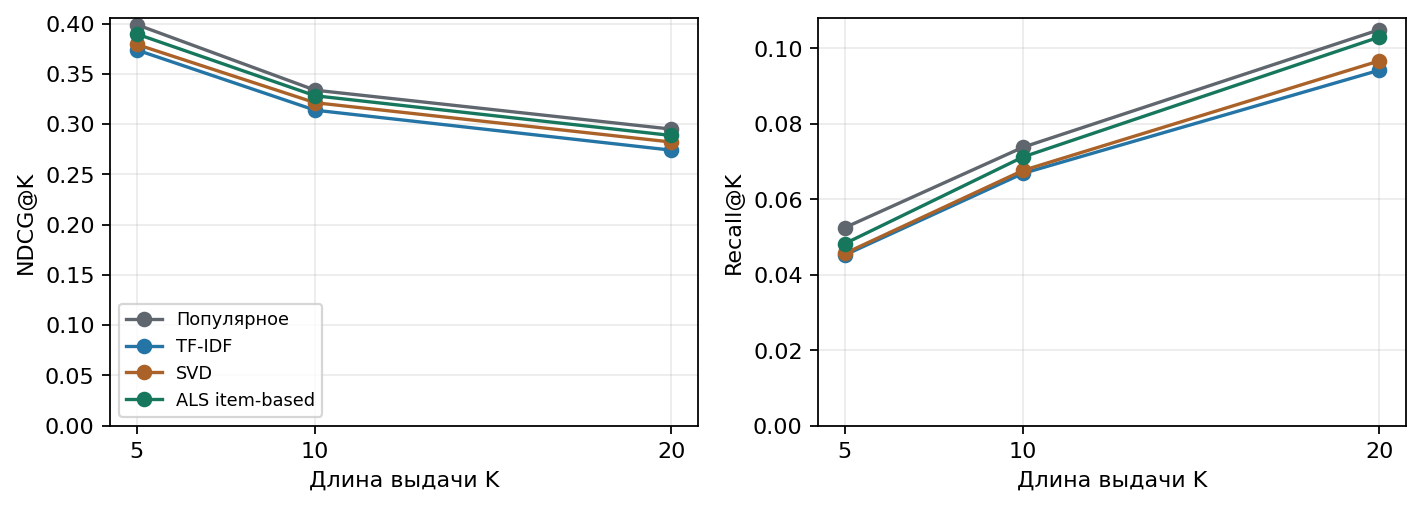

In [6]:
display(Image(filename=str(OUT / "ranking.png"), width=980))

*Рис. 2. NDCG и Recall в зависимости от длины выдачи. Ось Y начинается с нуля.*

У популярного Recall растёт с 0,0525 при K = 5 до 0,1050 при K = 20, а Precision падает с 0,3828 до 0,2448. Дополнительные позиции дают больше попаданий, но средняя доля попаданий в расширенном списке ниже. NDCG нормируется отдельно для каждого K, поэтому его снижение не означает, что первые пять позиций изменились.

При K = 20 разрыв по Recall между популярным и ALS — около 0,002. Длина выдачи меняет баланс точности и полноты, однако в среднем по 116 пользователям лидер на трёх проверенных K остаётся тем же.

## Качество по длине истории

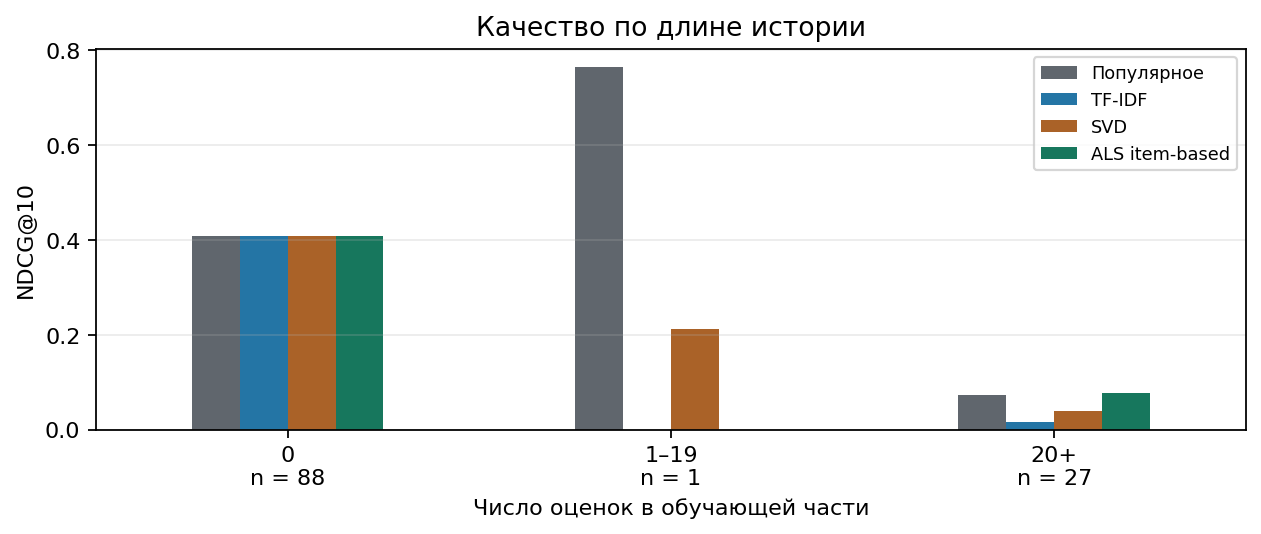

In [7]:
display(Image(filename=str(OUT / "segments.png"), width=980))

*Рис. 3. NDCG@10 по числу оценок до временного порога. Под числом оценок указано число пользователей.*

У 88 из 116 пользователей (75,9%) нет истории до порога. Все четыре модели дают им одинаковую выдачу и NDCG@10 = 0,4091. Поэтому общая метрика в основном описывает этот сценарий. В группе 1–19 оценок всего один пользователь, и её результат нельзя обобщать.

У 27 пользователей с 20+ оценками ALS имеет NDCG@10 = 0,0767 против 0,0722 у популярного. При этом Recall@10 у ALS ниже (0,0355 против 0,0412). ALS немного лучше располагает попадания в начале списка по NDCG, а популярное находит большую долю релевантного.

In [8]:
interval_rows = []
for label, entries in summary["bootstrap_ndcg"].items():
    for entry in entries:
        interval_rows.append({"Группа": label, "Модель": names[entry["model"]],
                              "Разница NDCG@10": entry["difference"],
                              "Нижняя граница": entry["low"], "Верхняя граница": entry["high"]})
display(pd.DataFrame(interval_rows).round(4))

,Группа,Модель,Разница NDCG@10,Нижняя граница,Верхняя граница
0,все,TF-IDF,-0.0199,-0.0407,-0.0051
1,все,SVD,-0.0125,-0.0309,0.0007
2,все,ALS item-based,-0.0056,-0.0296,0.0166
3,20+,TF-IDF,-0.0572,-0.1160,-0.0130
4,20+,SVD,-0.0331,-0.0904,0.0117
5,20+,ALS item-based,0.0044,-0.0806,0.0846


Интервалы получены парным бутстрэпом по пользователям, 2 000 повторов. Для ALS оба интервала включают ноль, поэтому преимущество в активной группе по этой выборке не установлено. У групп различаются и тестовые цели: медиана релевантных фильмов равна 42 без истории и 13 при 20+ оценках. Сравнивать модели надёжнее внутри одной группы.

## Покрытие и разнообразие

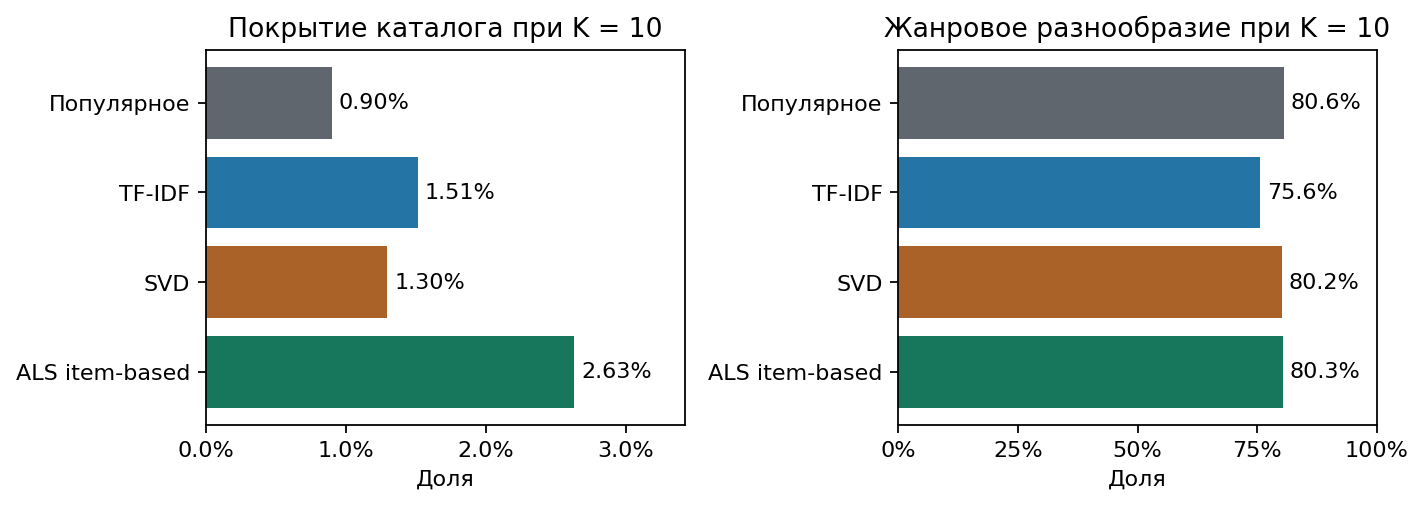

In [9]:
display(Image(filename=str(OUT / "catalog.png"), width=980))

*Рис. 4. Покрытие общего каталога и среднее попарное жанровое разнообразие при K = 10. Масштабы осей различаются.*

In [10]:
top10 = metrics[(metrics["segment"] == "все") & (metrics["k"] == 10)].copy()
display(pd.DataFrame({
    "Модель": top10["model"].map(names),
    "Фильмов в выдаче": (top10["coverage"] * summary["candidate_movies"]).round().astype(int),
    "Покрытие, %": (top10["coverage"] * 100).round(2),
    "Вне популярных 10%, %": (top10["tail_share"] * 100).round(1),
    "Жанровое разнообразие": top10["diversity"].round(3),
}).reset_index(drop=True))

,Модель,Фильмов в выдаче,"Покрытие, %","Вне популярных 10%, %",Жанровое разнообразие
0,Популярное,71,0.90,0.0,0.806
1,TF-IDF,119,1.51,19.0,0.756
2,SVD,102,1.30,1.6,0.802
3,ALS item-based,207,2.63,11.8,0.803


Покрытие — доля фильмов, появившихся хотя бы в одной выдаче. ALS показала 207 разных фильмов, популярное — 71. По жанровому разнообразию ALS близка к бейзлайну. Это два отдельных эффекта: разные пользователи могут получить больше разных фильмов, даже когда разнообразие внутри каждого списка почти не меняется.

TF-IDF даёт больше фильмов за пределами верхних 10% каталога по популярности (19,0% выдачи), но его списки наиболее однородны по жанрам (0,756). Разнообразие измерено средним расстоянием Жаккара между наборами жанров двух фильмов. Пары без жанровой разметки пропущены.

Выдача TF-IDF согласуется с риском сужения рекомендаций вокруг уже известных жанров и серий. Одноразовая офлайн-проверка показывает однородность списков. Чтобы измерить изменение интересов со временем, потребовались бы последовательные показы и реакции пользователей.

## Разбор двух выдач

Для иллюстрации взяты два случая с наибольшей разницей NDCG@10 между ALS и популярным в противоположных направлениях. Типичное качество отражено в таблице метрик по всем пользователям.

### Пользователь 601 · 27 оценок в истории

В истории есть высокие оценки у Finding Nemo и The Incredibles. ALS поставила Shrek на первое место, Good Will Hunting — на второе, V for Vendetta — на третье, The Sixth Sense — на четвёртое. Все четыре фильма получили позднее ≥ 4. У популярного было одно попадание, на девятой позиции. В этом случае сходство фильмов по аудитории подняло релевантные позиции в разных жанрах.

### Пользователь 15 · 16 оценок в истории

В обучении пользователь поставил Lethal Weapon 2 пять звёзд. Первые три позиции TF-IDF заняли другие части серии Lethal Weapon. Среди них нет тестовых попаданий. У ALS тоже нет попаданий в топ-10. Популярное поставило The Shawshank Redemption, Pulp Fiction и Forrest Gump на первые три позиции, и все три получили ≥ 4 в тесте. Всего у популярного семь попаданий.

In [11]:
for example in examples:
    print(f"Пользователь {example['user_id']} · оценок в истории: {example['train_ratings']}")
    rows = []
    for model, ranking in example["rankings"].items():
        hits = [f"{i}. {item['title']}" for i, item in enumerate(ranking["items"], 1) if item["hit"]]
        rows.append({"Модель": names[model], "Попаданий в топ-10": len(hits),
                     "NDCG@10": round(ranking["ndcg"], 4),
                     "Попадания с позициями": "; ".join(hits) or "—"})
    display(pd.DataFrame(rows))

Пользователь 601 · оценок в истории: 27


,Модель,Попаданий в топ-10,NDCG@10,Попадания с позициями
0,Популярное,1,0.0663,9. Raiders of the Lost Ark (Indiana Jones and ...
1,TF-IDF,0,0.0000,—
2,SVD,1,0.0636,10. Rear Window (1954)
3,ALS item-based,4,0.5638,1. Shrek (2001); 2. Good Will Hunting (1997); ...


Пользователь 15 · оценок в истории: 16


,Модель,Попаданий в топ-10,NDCG@10,Попадания с позициями
0,Популярное,7,0.7656,"1. Shawshank Redemption, The (1994); 2. Pulp F..."
1,TF-IDF,0,0.0000,—
2,SVD,2,0.2122,2. American History X (1998); 7. Shawshank Red...
3,ALS item-based,0,0.0000,—


Таблица показывает NDCG@10. Фильмы без поздней оценки ≥ 4 отмечены как непопадания. По этим данным нельзя сказать, что пользователь их посмотрел и отверг.

## Заключение и воспроизводимость

В общем временном тесте популярное выигрывает по NDCG@10. Для пользователей без истории оно уже даёт ту же выдачу, что и остальные модели. У пользователей с 20+ оценками ALS чуть выше по NDCG, но интервал разницы широкий. Измеренное преимущество ALS — охват: 207 фильмов вместо 71 при близком среднем NDCG.

Смена метода зависит от цели. Для приоритета точности в проверенном сценарии популярное остаётся отправной точкой. Для расширения охвата стоит отдельно проверить ALS на большей выборке пользователей с историей. TF-IDF на названиях и жанрах давал мало попаданий в этой группе и иногда заполнял верх списка частями одной серии.

### Границы выводов

Выводы относятся к одному архиву MovieLens и одному временному порогу. У оценок нет логов показов. Пользователь мог не оценить фильм, потому что не увидел его. В тесте оценивались известные к моменту отсечения фильмы, поэтому результат не описывает холодный старт фильма. Офлайн-метрики не измеряют реальное время просмотра.

### Повторный запуск

```text
python recsys.py --dataset movielens --model all --k 5 10 20 --evaluate
```

Артефакты прогона сохранены в results. metrics.csv содержит метрики по моделям, K и сегментам. В recs.json сохранены выдачи с отметками попаданий. summary.json содержит состав выборок, интервалы и контрольную сумму архива. В practice7.ipynb приведены таблицы, графики и пояснения.

### Источник

Harper F. M., Konstan J. A. The MovieLens Datasets: History and Context. ACM TiiS, 2015. DOI 10.1145/2827872. Архив MovieLens Latest Small, GroupLens.

[Описание датасета и условия использования](https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html)